1. 安装/导入必要库

In [37]:
# =====================================
# AI+地学课程设计版
# 南太行生态修复时空分析
# =====================================

import os
import re
import rasterio
import warnings
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from scipy.stats import skew,kurtosis

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

import shap

warnings.filterwarnings("ignore")

plt.rcParams['font.sans-serif']=['Microsoft YaHei']
plt.rcParams['axes.unicode_minus']=False

sns.set_theme(
    style="white",
    font="Microsoft YaHei"
)

2. 定义读取所有年份数据的函数

In [38]:
BASE_PATH = r"dasai\南太行数据"

FOREST_PATH = os.path.join(
    BASE_PATH,
    "适生林地占比"
)

CARBON_PATH = os.path.join(
    BASE_PATH,
    "碳储量"
)

FVC_PATH = os.path.join(
    BASE_PATH,
    "FVC"
)

OUT_DIR = os.path.join(
    BASE_PATH,
    "AI分析结果"
)

os.makedirs(
    OUT_DIR,
    exist_ok=True
)

3. 设定路径并读取数据（2013–2024）

In [39]:
import os
import re
import rasterio
import numpy as np
import pandas as pd
from tqdm import tqdm


def read_raster_samples(
        folder,
        var_name,
        sample_size=8000):

    all_df=[]

    files=os.listdir(folder)

    print(f"\n正在扫描 {folder}")
    print(f"发现文件数：{len(files)}")

    for tif in tqdm(files):

        # 只处理tif
        if not tif.lower().endswith(".tif"):
            continue

        years=re.findall(r"\d{4}", tif)

        if len(years)==0:
            print(f"跳过无法识别年份文件: {tif}")
            continue

        year=int(years[-1])

        path=os.path.join(folder,tif)

        try:

            with rasterio.open(path) as src:

                arr=src.read(
                    1,
                    masked=True
                )

                valid=np.where(
                    ~arr.mask
                )

                total=len(valid[0])

                if total==0:
                    print(f"空栅格: {tif}")
                    continue

                n=min(
                    sample_size,
                    total
                )

                idx=np.random.choice(
                    total,
                    n,
                    replace=False
                )

                rows=valid[0][idx]
                cols=valid[1][idx]

                values=arr[rows,cols]

                xs,ys=src.xy(
                    rows,
                    cols
                )

                temp=pd.DataFrame({

                    "lon":xs,
                    "lat":ys,
                    var_name:values,
                    "year":year

                })

                all_df.append(temp)

        except Exception as e:

            print(
                f"读取失败 {tif}"
            )

            print(e)

    if len(all_df)==0:

        raise ValueError(
            f"{folder} 中没有成功读取任何tif"
        )

    return pd.concat(
        all_df,
        ignore_index=True
    )

4. 按年份和位置合并三个变量

In [40]:
forest_df = read_raster_samples(
    FOREST_PATH,
    "forest"
)

carbon_df = read_raster_samples(
    CARBON_PATH,
    "carbon"
)

fvc_df = read_raster_samples(
    FVC_PATH,
    "fvc"
)

print(forest_df.head())
print(forest_df.shape)
print(carbon_df.head())
print(carbon_df.shape)
print(fvc_df.head())
print(fvc_df.shape)


正在扫描 dasai\南太行数据\适生林地占比
发现文件数：100


100%|██████████| 100/100 [00:08<00:00, 12.28it/s]



正在扫描 dasai\南太行数据\碳储量
发现文件数：58


100%|██████████| 58/58 [00:10<00:00,  5.78it/s]



正在扫描 dasai\南太行数据\FVC
发现文件数：63


100%|██████████| 63/63 [00:09<00:00,  6.57it/s]

             lon           lat  forest  year
0  766690.216954  3.878207e+06       1  2019
1  680530.216954  3.788897e+06       1  2019
2  668620.216954  3.784667e+06       1  2019
3  774250.216954  3.811607e+06       0  2019
4  828430.216954  3.892817e+06       0  2019
(48000, 4)
             lon           lat     carbon  year
0  819910.216954  3.891767e+06   6.716700  2019
1  823870.216954  3.880247e+06   6.716700  2019
2  717940.216954  3.762257e+06   8.352900  2019
3  687940.216954  3.756167e+06   8.352900  2019
4  648340.216954  3.786587e+06  13.733999  2019
(48000, 4)
             lon           lat       fvc  year
0  789400.216954  3.867077e+06  0.700664  2019
1  783220.216954  3.811847e+06  0.714757  2019
2  801880.216954  3.892277e+06  0.490537  2019
3  803950.216954  3.819197e+06  0.000000  2019
4  776560.216954  3.895217e+06  0.625838  2019
(48000, 4)


In [41]:
for d in [forest_df,carbon_df,fvc_df]:

    d["lon"]=d["lon"].round(4)
    d["lat"]=d["lat"].round(4)

df=forest_df.merge(
    carbon_df,
    on=["lon","lat","year"]
)

df=df.merge(
    fvc_df,
    on=["lon","lat","year"]
)

print(df.shape)

(0, 6)


5. 数据清洗 & 描述性统计

In [42]:
def remove_iqr(df,col):

    q1=df[col].quantile(.25)
    q3=df[col].quantile(.75)

    iqr=q3-q1

    lower=q1-1.5*iqr
    upper=q3+1.5*iqr

    return df[
        (df[col]>=lower)
        &
        (df[col]<=upper)
    ]

for c in [

    "forest",
    "carbon",
    "fvc"

]:

    df=remove_iqr(df,c)


In [43]:
stats=pd.DataFrame({

    "均值":df[
        ["forest","carbon","fvc"]
    ].mean(),

    "标准差":df[
        ["forest","carbon","fvc"]
    ].std(),

    "变异系数":df[
        ["forest","carbon","fvc"]
    ].std()
    /
    df[
        ["forest","carbon","fvc"]
    ].mean(),

    "偏度":[
        skew(df[c])
        for c in
        ["forest","carbon","fvc"]
    ],

    "峰度":[
        kurtosis(df[c])
        for c in
        ["forest","carbon","fvc"]
    ]

})

stats.to_excel(
    os.path.join(
        OUT_DIR,
        "描述统计.xlsx"
    )
)

6. 时间序列趋势图（美观）

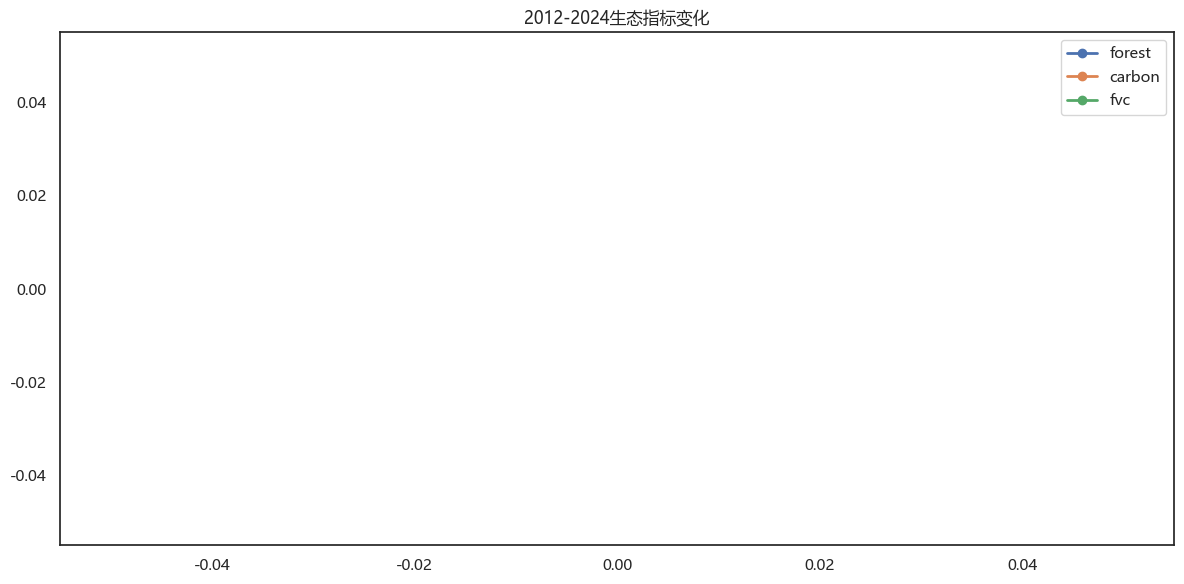

In [44]:
year_mean=df.groupby(
    "year"
)[
    ["forest","carbon","fvc"]
].mean()

plt.figure(
    figsize=(12,6)
)

for col in year_mean.columns:

    plt.plot(
        year_mean.index,
        year_mean[col],
        marker='o',
        linewidth=2,
        label=col
    )

plt.legend()

plt.title(
    "2012-2024生态指标变化"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT_DIR,
        "图1_时间趋势.png"
    ),
    dpi=300
)

7. 相关性热图（含年份）

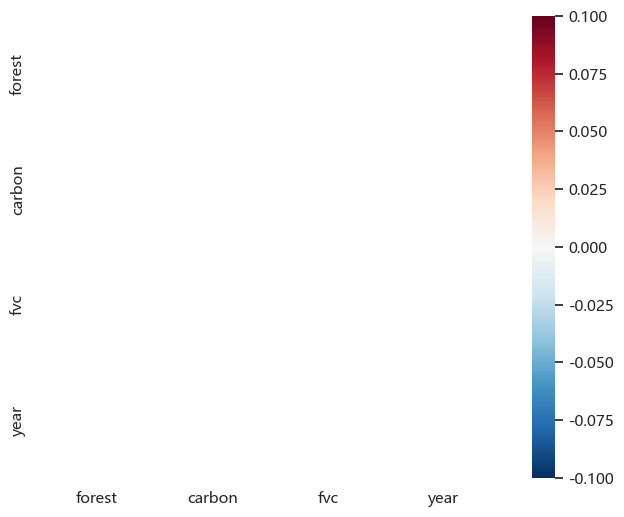

In [45]:
corr=df[
    [
        "forest",
        "carbon",
        "fvc",
        "year"
    ]
].corr()

mask=np.triu(
    np.ones_like(corr)
)

plt.figure(
    figsize=(8,6)
)

sns.heatmap(

    corr,

    mask=mask,

    cmap="RdBu_r",

    annot=True,

    square=True

)

plt.savefig(
    os.path.join(
        OUT_DIR,
        "图2_相关性热图.png"
    ),
    dpi=300
)

8. PCA

In [47]:
X=df[
[
"forest",
"carbon",
"fvc"
]
]

X_std=StandardScaler().fit_transform(X)

pca=PCA(
    n_components=2
)

pc=pca.fit_transform(
    X_std
)

df["PC1"]=pc[:,0]
df["PC2"]=pc[:,1]

ValueError: Found array with 0 sample(s) (shape=(0, 3)) while a minimum of 1 is required by StandardScaler.

In [ ]:
plt.figure(
    figsize=(8,6)
)

plt.scatter(

    df["PC1"],
    df["PC2"],

    s=10,

    alpha=.5

)

plt.xlabel(
    f"PC1 {pca.explained_variance_ratio_[0]*100:.1f}%"
)

plt.ylabel(
    f"PC2 {pca.explained_variance_ratio_[1]*100:.1f}%"
)

plt.savefig(
    os.path.join(
        OUT_DIR,
        "图3_PCA.png"
    ),
    dpi=300
)

9. 图4 自动寻找最佳K

In [ ]:
scores=[]

for k in range(2,8):

    km=KMeans(
        n_clusters=k,
        random_state=42
    )

    label=km.fit_predict(
        X_std
    )

    scores.append(

        silhouette_score(
            X_std,
            label
        )

    )

10. KMeans聚类

best_k=np.argmax(scores)+2

kmeans=KMeans(
    n_clusters=best_k,
    random_state=42
)

df["cluster"]=kmeans.fit_predict(
    X_std
)

In [ ]:
plt.figure(
    figsize=(8,6)
)

sns.scatterplot(

    data=df,

    x="PC1",

    y="PC2",

    hue="cluster",

    palette="Set2",

    s=20

)

plt.savefig(
    os.path.join(
        OUT_DIR,
        "图5_聚类结果.png"
    ),
    dpi=300
)

11. 随机森林

In [ ]:
X=df[
[
"forest",
"fvc",
"year"
]
]

y=df["carbon"]

X_train,X_test,y_train,y_test=\
train_test_split(
X,
y,
test_size=.3,
random_state=42
)

rf=RandomForestRegressor(

n_estimators=300,

max_depth=10,

n_jobs=-1,

random_state=42

)

rf.fit(
X_train,
y_train
)

pred=rf.predict(
X_test
)

print(
"R²=",
r2_score(
y_test,
pred
)
)

SHAP

In [ ]:
explainer=shap.TreeExplainer(
    rf
)

shap_values=explainer.shap_values(
    X_test
)

shap.summary_plot(

    shap_values,

    X_test,

    show=False

)

plt.savefig(
    os.path.join(
        OUT_DIR,
        "图7_SHAP.png"
    ),
    dpi=300,
    bbox_inches='tight'
)